# Лекция 8. Быстрое дифференцирование

> 🧭 **Пройдено до этого.** Лекция 6 — конечные разности, лекция 7 —
> комплексный шаг: обе дифференцируют «чёрный ящик», обе платят
> прогонами функции.

**⚠️ В этой лекции:**

- вспомним **численное** дифференцирование;
- дадим строгое определение **символьного** и посмотрим, что получается
  на практике и сколько это стоит 🕒;
- введём **автоматическое дифференцирование (AD)** — движок, на котором
  обучаются все современные нейросети;
- разберём **прямой режим** (касательные, дуальные числа), **JVP** и
  **обратный режим** (сопряжённые, лента, VJP) — математически и на
  актуальном PyTorch;
- заглянем **под капот PyTorch**: тензоры, `.grad`, граф вычислений,
  autograd engine, вычисление JVP/VJP под капотом;
- посчитаем **сложность по времени и памяти** обоих режимов;
- в конце — **задачник для ПЗ** с развёрнутыми решениями для преподавателя.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
plt.rcParams['figure.dpi'] = 110
print('numpy', np.__version__, '| torch', torch.__version__)


numpy 2.5.4 | torch 2.11.0+cpu


## 1. 🏁 Численное дифференцирование: вспомним

Лекции 6–7 считали производную по **двум пробам функции**:
$$
f'(x) \approx \frac{f(x+h)-f(x-h)}{2h}, \qquad
f''(x) \approx \frac{f(x+h)-2f(x)+f(x-h)}{h^{2}},
$$
с усечением $\mathcal{O}(h^{2})$; суммарная ошибка — $U$-образная
кривая: при маленьком $h$ в неё заливается машинная арифметика,
потолок — порядка $\sqrt{\varepsilon_{\text{маш}}}$ 🧱.

- Каждой частной производной — **свой прогон программы**: $n$
  производных — $n + 1$ прогонов функции.
- Комплексный шаг (Л7) дал машинную точность, но оставил $n$ прогонов
  и потребовал аналитичности.

Для функции с $n \sim 10^{6}\dots10^{11}$ параметрами (нейросеть!)
это убивает метод. Поднимаемся по лестнице: **символьное →
автоматическое.**


## 2. 📝 Символьное дифференцирование: точно по правилам

Прежде чем вводить AD, честно определим его предшественника. Здесь
*вход и выход — не числа, а формулы*.

### 📖 Определение

Пусть $T$ — множество корректных **деревьев выражений**, построенных
из констант, переменных $x_1, \dots, x_n$ и операций сигнатуры
$\Sigma = \{+,-,\times,/,-_{\text{унарн}}, \sin, \exp, \log,
\dots\}$. **Символьное дифференцирование** — оператор
$D \colon T \to T$, который по всякому дереву $f \in T$ возвращает
дерево $D[f]$ такое, что **для каждого $i$ и каждой точки $\mathbf x$**

$$
\mathrm{val}\bigl(D[f]\bigr)(\mathbf x) =
\frac{\partial f}{\partial x_i}(\mathbf x),
$$

где $\mathrm{val}(\cdot)$ — численная оценка дерева. Задаётся $D$
**структурно и рекурсивно**: константа даёт $0$; переменная $x_i$
даёт $1$, прочие переменные — $0$; а для композиции действует правило
производной сложной функции

$$
D[w \circ \varphi] = (D[w] \circ \varphi) \cdot D[\varphi].
$$

Примеры: $D[x \sin x] = \sin x + x\cos x$,
$D[\exp(x^{2})] = 2x\,e^{x^{2}}$.

Результат — **новая формула**: её можно снова дифференцировать,
упрощать, подставлять, интегрировать, решать уравнения. Но каждое
правило умножения и композиции **дублирует подвыражения** — посмотрим,
чем это кончается, на живом примере 🧪: для $f(x) = x\sin x$ и
семейства $f_0 = x$, $f_k = f_{k-1}^{2} + 1$ будем растить $f_k$,
дифференцировать и измерять длину формулы, время дифференцирования и
время подстановки числа.


In [1]:
import time
import sympy as sp            # символьная математика в Python (pip install sympy)

x = sp.symbols('x')
f = x * sp.sin(x)
df = sp.diff(f, x)            # производная — снова формула
print('f  =', f)
print('Df =', df)
print()

# семейство f_k = f_{k-1}^2 + 1: глубина растёт, меряем всё
print(f"{'k':>3} | {'len(f_k)':>8} | {'len(Df_k)':>9} | {'diff, ms':>8} | {'подстановка, ms':>15}")
g = x
for k in range(1, 11):
    g = g ** 2 + 1
    t0 = time.perf_counter()
    dg = sp.diff(g, x)
    t_diff = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    val = float(dg.subs(x, 1.3))
    t_subs = (time.perf_counter() - t0) * 1000
    print(f'{k:3d} | {len(str(g)):8d} | {len(str(dg)):9d} | {t_diff:8.1f} | {t_subs:15.1f}')
print()
print('уже к k = 10 формула производной в 4-5 раз длиннее самой функции:')
print('каждое правило дифференцирования дублирует подвыражения.')


f  = x*sin(x)
Df = x*cos(x) + sin(x)

  k | len(f_k) | len(Df_k) | diff, ms | подстановка, ms
  1 |        8 |         3 |      2.4 |             0.4
  2 |       17 |        14 |      3.5 |             0.6
  3 |       26 |        34 |      3.4 |             0.7
  4 |       35 |        64 |      3.7 |             0.7
  5 |       44 |       102 |      3.6 |             0.7
  6 |       53 |       149 |      4.3 |             0.9
  7 |       62 |       206 |      4.1 |             0.8
  8 |       71 |       271 |      4.6 |             0.8
  9 |       80 |       345 |      5.2 |             1.0
 10 |       89 |       429 |      5.0 |             1.0

уже к k = 10 формула производной в 4-5 раз длиннее самой функции:
каждое правило дифференцирования дублирует подвыражения.


### 💥 Что выходит у символьного

- **Формула раздувается.** Правило $D[f_k] = 2 f_{k-1} \cdot
  D[f_{k-1}]$ на каждом шаге несёт **целое дерево $f_{k-1}$**:
  дублёж накапливается, и для многих семейств рост $D[f]$ —
  **экспоненциальный** 🎈 (башни композиций
  $\exp \circ \exp \circ \dots$); спасает агрессивное
  упрощение, но оно само NP-трудно.
- **Дерево нужно ещё и считать.** Дубликаты подвыражений вычисляются
  заново: переиспользования нет, оценка $D[f]$ заметно дороже оценки $f$.
- **Результат — формула, а не число.** Для градиента от
  $\Psi \sim 10^{8}$-операционной программы символьная производная —
  гигабайты: хранить невозможно.
- **Функция — это код.** В ML «функция» — десятки строк Python с
  матричными операциями, ветвлениями и циклами: символьный
  дифференциатор её не видит.

Вывод: для алгебры — прекрасно, для градиента программы с миллионами
параметров — нет. Нужно что-то, что (1) работает с **кодом**, (2) не
строит формул, (3) переиспользует общие подвыражения, (4) выдаёт
**числа**. Это и есть AD.


## 3. ⚡ Автоматическое дифференцирование (AD)

### 📖 Определение

Пусть программа вычисляет $f \colon \mathbb{R}^{n} \to
\mathbb{R}^{m}$, $(x_1, \dots, x_n) \mapsto (y_1, \dots, y_m)$,
с любыми операциями: сложение, умножение, `matmul`, `exp`, `if` и
циклы — AD работает со всем этим. **Автоматическое
дифференцирование** — семейство алгоритмов, которые вычисляют
численные значения элементов якобиана $J(x) \in
\mathbb{R}^{m \times n}$ (и его произведений на векторы) для
программы, а не для формулы:

1. разбить программу на последовательность **примитивов** с известными
   локальными производными;
2. сохранять промежуточные значения (или пересчитывать их позже);
3. цепное правило применять **примитив за примитивом** на фактической
   трассе выполнения;
4. **переиспользовать** общие подвыражения.

На выходе — **числа** с машинной точностью 🎁: усечения нет (как у
разностей), формулы не раздуваются (как у символьного — дерево даже
не строится), и код может быть любым.

Терминология: английское — **automatic differentiation, AD**;
русскоязычное — **«быстрое дифференцирование»** (термин школы
Евтушенко, ВЦ РАН). «Быстрое» — про **асимптотику**: градиент
обойдётся в константное число проходов самой функции (теорема
Баура–Штрассена, §9), а не в $n$ прогонов.

$J$ целиком почти никогда не нужна — работают её произведения на
векторы. За каждое отвечает свой режим AD: **прямой проход** (JVP) и
**обратный проход** (VJP). Математика обоих — дальше.


## 4. ➡️ Прямой режим: касательные

Идея: **каждая величина тащит касательную**. Вместе со значением
$v_i \in \mathbb{R}$ (primal) храним касательную
$\tilde v_i \in \mathbb{R}$ (tangent) — производную $v_i$ вдоль
вектора сдвига входов $\tilde{\mathbf x}$. Для вершины
$v_i = \varphi_i(v_{i_1}, \dots, v_{i_{k_i}})$ касательная несёт
правило

$$
\tilde v_i \;=\; \sum_{j \le k_i}
\frac{\partial \varphi_i}{\partial v_{i_j}}\, \tilde v_{i_j},
$$

то есть цепное правило, «перемноженное» на входные касательные. Если
сдвиг $\tilde{\mathbf x} = e_j$ и прочие касательные нулевые, то на
выходе

$$
\tilde y = J(\mathbf x)\, e_j = \text{$j$-й столбец } J.
$$

> 🧩 **Геометрия.** Касательная — это производная по направлению:
> $\tilde y = \left. \frac{d}{ds} f(x + s\,\tilde x)
> \right|_{s=0}$. Значения и касательные идут по графу слева
> направо, в одном прогоне.

Как реализовать правило касательной в коде, не переписывая ни одной
строки функции? Арифметический ответ: **дуальные числа**.


### 🧮 Дуальные числа: арифметика касательных

**Дуальное число** — пара $a + b\,\varepsilon$ со значением $a$ и
касательной $b$; новая единица
$$
\varepsilon^{2} = 0.
$$
(Родственник комплексного шага из лекции 7, только новая ось не
«крутится» ($i^{2} = -1$), а «упирается в ноль» 🧪.) Ряд Тейлора
**обрывается сам**:
$$
f(x + \varepsilon) = f(x) + \varepsilon f'(x),
$$
вещественная часть — значение, «$\varepsilon$-часть» — точная
касательная, без остатка $O(h^{2})$. Формально: программа
исполняется в кольце $\mathbb{R}[\varepsilon]/\varepsilon^{2}$
вместо $\mathbb{R}$; прогон с касательной $(1, 0)$ даёт
$\partial f/\partial x_1$, с $(0, 1)$ — $\partial f/\partial
x_2$, с $(d_1, d_2)$ — производную по направлению $d$.

Арифметика выводится механически; например
$$
(a+b\varepsilon)(c+d\varepsilon) = ac + (ad+bc)\varepsilon,
\qquad
\sin(a+b\varepsilon) = \sin a + b\cos(a)\,\varepsilon .
$$
Коэффициент при $\varepsilon$ воспроизводит правило произведения.
**Перегружаем** (operator overloading) элементарные операции — и
исходная программа выдаёт значение и производную за один прогон.

Цена: **один прогон на каждое касательное направление**.


In [1]:
import math

class Dual:
    # дуальное число: значение (val) + касательная (dval)
    def __init__(self, val, dval=0.0):
        self.val, self.dval = val, dval
    def __add__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val + o.val, self.dval + o.dval)
    __radd__ = __add__
    def __mul__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val * o.val, self.val * o.dval + o.val * self.dval)
    __rmul__ = __mul__

def d_sin(u):
    u = u if isinstance(u, Dual) else Dual(u)
    return Dual(math.sin(u.val), math.cos(u.val) * u.dval)

def f(x1, x2):
    return x1 * x2 + d_sin(x1)

a, b = Dual(2.0, 1.0), Dual(3.0, 0.0)   # касательная e1: трогаем x1
f1 = f(a, b)
a, b = Dual(2.0, 0.0), Dual(3.0, 1.0)   # касательная e2: трогаем x2
f2 = f(a, b)

print(f'f      = {f1.val:.10f}   (точно: 6 + sin 2)')
print(f'df/dx1 = {f1.dval:.10f}   аналит. = 3 + cos 2 = {3 + math.cos(2):.10f}')
print(f'df/dx2 = {f2.dval:.10f}   аналит. = 2               ')
print('шага h нет вообще — нечему накапливать ошибку; точность машинная')


f      = 6.9092974268   (точно: 6 + sin 2)
df/dx1 = 2.5838531635   аналит. = 3 + cos 2 = 2.5838531635
df/dx2 = 2.0000000000   аналит. = 2               
шага h нет вообще — нечему накапливать ошибку; точность машинная


### 🐍 Дуальные числа в PyTorch

В актуальном PyTorch прямой режим — не тайна за семью печатями:
`torch.autograd.forward_ad` открывает нижний этаж. Контекст-менеджер
`dual_level()` создаёт уровень касательных, `make_dual(primal,
tangent)` упаковывает тензор в **дуальный тензор** (primal + tangent),
`unpack_dual` читает их обратно. Это то же кольцо
$\mathbb{R}[\varepsilon]/\varepsilon^{2}$, собранное на тензорах и
векторизованное: каждая операция внутри `dual_level` обрабатывает
обе части сразу.


In [1]:
import math
import torch
from torch.autograd.forward_ad import dual_level, make_dual, unpack_dual

torch.manual_seed(0)

def f(x):
    return x * torch.sin(x) + torch.tanh(x)

x = torch.tensor([1.0, 2.0])
v = torch.tensor([1.0, 0.0])          # касательная: трогаем первую координату

with dual_level():
    x_dual = make_dual(x, v)          # дуальный тензор: primal + tangent
    y      = f(x_dual)               # код функции менять НЕ нужно!
    primal, tangent = unpack_dual(y)

print('primal :', [round(a, 6) for a in primal.tolist()])
print('tangent:', [round(a, 6) for a in tangent.tolist()])
print('аналитика: df/dx = sin x + x·cos x + sech²x,')
print('J диагональна → J[:,0] = [df/dx(x1), 0.0]')
a1 = math.sin(1) + 1 * math.cos(1) + (1 - math.tanh(1) ** 2)
print('точный столбец e1     :', [round(a1, 6), 0.0])


primal : [1.603065, 2.782622]
tangent: [1.801748, 0.0]
аналитика: df/dx = sin x + x·cos x + sech²x,
J диагональна → J[:,0] = [df/dx(x1), 0.0]
точный столбец e1     : [1.801748, 0.0]


## 5. 🧭 JVP: jacobian–vector product

Прямой прогон всегда несёт **произведение якобиана на вектор
касательных**; оформим его как операцию с именем:

### 📖 Определение

Для $f \colon \mathbb{R}^{n} \to \mathbb{R}^{m}$, точки
$\mathbf x$ и вектора $v \in \mathbb{R}^{n}$ **JVP** — пара

$$
\mathrm{JVP}(f,\; \mathbf x,\; v) \;=\;
\bigl( f(\mathbf x),\; J(\mathbf x)\, v \bigr)
\in \mathbb{R}^{m} \times \mathbb{R}^{m},
$$

то есть одним проходом возвращаем и значение $f(\mathbf x)$, и
производную в направлении $v$ — ровно то, что дуальные числа дают
для сдвига $f(\mathbf x + \varepsilon v)$ 🪄.

- $v = e_j$ — $j$-й **столбец** $J$: производные всех выходов по
  одной переменной;
- произвольный $v$ — точная производная по комбинированному
  направлению;
- весь якобиан — $n$ прогонов с $v = e_1, \dots, e_n$;
- вложим JVP в градиент обратного прохода — получим **HVP**:
  произведение Гессиана на вектор без $O(n^{2})$ памяти 🧵
  (метод Пирлмуттера).

### 🐍 Как вычислять на PyTorch

Актуальный интерфейс — функциональный API **`torch.func`** (в
PyTorch с 2.x):

- `torch.func.jvp(f, (x,), (v,))` — сразу и primal, и tangent;
- `torch.func.jacfwd(f)(x)` — весь якобиан прямым режимом
  (это `vmap` поверх JVP по базису $e_1, \dots, e_n$).


In [1]:
import torch
torch.manual_seed(0)

def f(x):
    return x * torch.sin(x) + torch.tanh(x)    # программа R^n -> R^n

x = torch.tensor([1.0, 2.0])
E = torch.eye(2)

# пара primal + tangent одним проходом
p, t = torch.func.jvp(f, (x,), (E[0],))
print('jvp по e1: primal ', [round(a, 6) for a in p.tolist()])
print('           tangent', [round(a, 6) for a in t.tolist()])
print('jvp по e2: tangent', [round(a, 6)
      for a in torch.func.jvp(f, (x,), (E[1],))[1].tolist()])

# весь якобиан: jacfwd = vmap поверх JVP по базису
J = torch.func.jacfwd(f)(x)
print('J (jacfwd) =')
print([[round(a, 5) for a in row] for row in J.tolist()])

cols = torch.stack([torch.func.jvp(f, (x,), (E[i],))[1] for i in range(2)])
print('jacfwd.T == столбцы из jvp :', bool(torch.allclose(J.T, cols, atol=1e-6)))


jvp по e1: primal  [1.603065, 2.782622]
           tangent [1.801748, 0.0]
jvp по e2: tangent [0.0, 0.147655]
J (jacfwd) =
[[1.80175, 0.0], [0.0, 0.14765]]
jacfwd.T == столбцы из jvp : True


> ⚙️ **Под капотом `torch.func.jvp`.** Интерпретатор переводит
> тензоры в «дуальный режим» (уровни касательных из
> `torch.autograd.forward_ad`): каждый тензор несёт пару primal +
> tangent, операции идут по правилам дуальных чисел §4, а лента
> **не ведётся вовсе** — память $O(1)$. Дуальные числа §4, собранные
> на тензорах и векторизованные. 💭


## 6. ⬅️ Обратный режим: сначала вперёд, потом назад

Ниша — функция с **малым числом выходов и огромным числом входов**:
$n \sim 10^{6}\dots10^{11}$ параметров против одного скаляра
потерь. Каждой промежуточной величине приписываем **сопряжённую**
(adjoint)

$$
\bar v_i = \frac{\partial f}{\partial v_i},
$$

«чувствительность» узла: на сколько изменится $f$ при малом изменении
$v_i$. Локальное правило у каждой операции — кусочек цепного правила:

$$
c = g(a) \;\Rightarrow\;
\bar a \,{+}{=}\, \bar c \cdot g'(a),
\qquad
c = g(a, b) \;\Rightarrow\;
\bar a \,{+}{=}\, \bar c\,\partial_a g,\;\;
\bar b \,{+}{=}\, \bar c\,\partial_b g .
$$

Например: $c = a \cdot b \Rightarrow \bar a \,{+}{=}\,
\bar c\,b$, $\bar b \,{+}{=}\, \bar c\,a$;
$c = \sin a \Rightarrow \bar a \,{+}{=}\, \bar c\cos a$;
$c = a + b \Rightarrow \bar a \,{+}{=}\, \bar b \,{+}{=}\,
\bar c$; у выхода $\bar f = 1$.

Замечаете засаду? Правило для $\bar a$ использует **значения**
других узлов ($b$, $a$): их надо иметь к моменту обратного прохода.
Поэтому порядок таков:

**1. Forward-проход.** Считаются все $v_i$ и фиксируются зависимости
между операциями (лента, tape — идея Венгерта, 1964).

**2. Backward-проход.** Стартуем с $\bar v_L = 1$ и обходим вершины
в **обратном топологическом порядке** (от выхода к входам); для
каждого ребра $v_j \to v_i$ — накопление:

$$
\bar v_j \;{+}{=}\; \bar v_i \cdot
\frac{\partial v_i}{\partial v_j}.
$$

Знак «${+}{=}$» принципиален 🔍: переменная может влиять на результат
несколькими путями (в примере ниже $x_1$ — и через $u$, и через $v$),
полная производная — **сумма вкладов всех путей**.

### 📼 Лента целиком

Прогоним сквозной пример $f(x_1, x_2) = x_1 x_2 + \sin x_1$ по обеим
фазам и увидим: backward — та же трасса, проигранная в обратную
сторону 📼.

| $n$° | операция | значение при $x_1 = 2$, $x_2 = 3$ |
|---|---|---|
| $-2$ | $v_{-2} = x_1$ | $2$ |
| $-1$ | $v_{-1} = x_2$ | $3$ |
| $1$ | $v_1 = v_{-2} \cdot v_{-1}$ | $6$ |
| $2$ | $v_2 = \sin v_{-2}$ | $\sin 2$ |
| $3$ | $v_3 = v_1 + v_2$ | $6 + \sin 2$ |

Обратный проход начинается с $\bar v_3 = 1$, далее локальные
производные и накопление:

$$
\bar v_2 = 1,\qquad \bar v_1 = 1,\qquad
\bar v_{-1} \,{+}{=}\, \bar v_1 \cdot v_{-2} = 2,
\qquad
\bar v_{-2} \,{+}{=}\, \bar v_1 \cdot v_{-1} +
\bar v_2 \cos v_{-2} = 3 + \cos 2.
$$

Итог: $\nabla f = (3 + \cos 2,\; 2)$ — обе компоненты получены
**совместно**, за один обратный проход. Перегружаем операции — и
сквозной пример считается целиком:


In [1]:
import math

class Var:
    # узел графа: значение + parents (узел, локальная производная) + adjoint
    def __init__(self, val, parents=()):
        self.val, self.parents, self.grad = val, parents, 0.0

    def __add__(self, o):
        o = o if isinstance(o, Var) else Var(o)
        return Var(self.val + o.val, ((self, 1.0), (o, 1.0)))
    def __mul__(self, o):
        o = o if isinstance(o, Var) else Var(o)
        return Var(self.val * o.val, ((self, o.val), (o, self.val)))
    def sin(self):
        return Var(math.sin(self.val), ((self, math.cos(self.val)),))

    def backward(self):
        # топологический порядок обхода (без рекурсии)
        order, seen = [], set()
        stack = [(self, False)]
        while stack:
            node, done = stack.pop()
            if done:
                order.append(node); continue
            if id(node) in seen:
                continue
            seen.add(id(node))
            stack.append((node, True))
            for parent, _ in node.parents:
                if id(parent) not in seen:
                    stack.append((parent, False))
        self.grad = 1.0                    # сопряжённая выхода = 1
        for node in reversed(order):       # от выхода к входам
            for parent, local in node.parents:
                parent.grad += local * node.grad    # {+}{=}: накапливаем!

x1, x2 = Var(2.0), Var(3.0)
u = x1 * x2        # c = a*b:  локальные производные (b, a)
v = x1.sin()       # c = sin a: локальная производная cos a
f = u + v
f.backward()

print('узел | значение | adjoint (вычислено) | вручную')
print(f' x1  |    2     | {x1.grad:.6f}         | 3 + cos 2 = {3 + math.cos(2):.6f}')
print(f' x2  |    3     | {x2.grad:.6f}         | 2         = {2.0:.6f}')
print(f' u   |    6     | {u.grad:.6f}         | 1         = {1.0:.6f}')
print(f' v   |  sin 2   | {v.grad:.6f}          | 1         = {1.0:.6f}')


узел | значение | adjoint (вычислено) | вручную
 x1  |    2     | 2.583853         | 3 + cos 2 = 2.583853
 x2  |    3     | 2.000000         | 2         = 2.000000
 u   |    6     | 1.000000         | 1         = 1.000000
 v   |  sin 2   | 1.000000          | 1         = 1.000000


Сопряжённые совпали ✅. Внутри `Var.backward` — лента (обход графа в
топологическом порядке) и накопление «${+}{=}$»: платим памятью
промежуточных значений, забираем **все** частные производные сразу.
Двадцать строк — и уже настоящий обратный режим.

### 🕸️ Backpropagation: слоистая развёртка обратного режима

Обратный режим для слоистых нейросетей имеет собственное имя —
**backpropagation**. Пусть
$$
v_0 = x, \qquad
v_{k+1} = \varphi\bigl(W_{k+1} v_k + b_{k+1}\bigr), \qquad
L = \ell(v_K, y),
$$
и введём **ошибки слоёв**
$$
\delta_k = \frac{\partial L}{\partial z_k}, \qquad
z_{k+1} = W_{k+1} v_k + b_{k+1}.
$$
Для выходного слоя $\delta_K$ определяется потерей и активацией;
для внутренних цепное правило даёт рекурсию
$$
\delta_k = \bigl(W_{k+1}^{\top}\delta_{k+1}\bigr) \odot
\varphi'(z_k), \qquad
\frac{\partial L}{\partial W_{k+1}} = \delta_{k+1}\, v_k^{\top},
\qquad
\frac{\partial L}{\partial b_{k+1}} = \delta_{k+1},
$$
где $\odot$ — покомпонентное произведение.

Важно: формулы δ — **не отдельный метод дифференцирования**. Это
обратный режим, применённый к конкретному слоистому графу. AD поэтому
одинаково работает с ветвлениями, residual-связями, свёртками и
attention: он не смотрит на «слои», он идёт по графу. Публикация
Румельхарта, Хинтона и Уильямса (1986) сделала backprop знаменитым,
но обратный режим сформулировали раньше, и применим он шире.

Свяжем формулы с кодом: двухслойная сеть, δ-правила руками против
`autograd`:


In [1]:
import torch
torch.manual_seed(1)

D, H = 7, 5
x  = torch.randn(D)
W1 = torch.randn(H, D, requires_grad=True); b1 = torch.randn(H, requires_grad=True)
W2 = torch.randn(1, H, requires_grad=True); b2 = torch.randn(1, requires_grad=True)
y  = 0.4 * x.mean()

z1 = W1 @ x + b1;  v1 = torch.tanh(z1)     # прямой проход
z2 = W2 @ v1 + b2
J = ((z2 - y) ** 2).sum()
J.backward()

# тот же обратный проход руками: правила δ
d2 = 2 * (z2 - y)                              # δ₂ (слой потерь)
g_W2 = d2[:, None] * v1[None, :]               # L/W2 = δ₂ v₁ᵀ
g_b2 = d2.clone()                              # L/b2 = δ₂
d1 = (W2.T @ d2) * (1 - torch.tanh(z1) ** 2)   # δ₁ = (W₂ᵀδ₂) ⊙ φ'(z₁)
g_W1 = d1[:, None] * x[None, :]                # L/W1 = δ₁ xᵀ
g_b1 = d1.clone()                              # L/b1 = δ₁

checks = [('W1', g_W1, W1.grad), ('b1', g_b1, b1.grad),
          ('W2', g_W2, W2.grad), ('b2', g_b2, b2.grad)]
for name, manual, auto in checks:
    print(f'{name}: max |δ-формулы - autograd| = {(manual - auto).abs().max().item():.2e}',
          '| совпало:', bool(torch.allclose(manual, auto, atol=1e-6)))


W1: max |δ-формулы - autograd| = 0.00e+00 | совпало: True
b1: max |δ-формулы - autograd| = 0.00e+00 | совпало: True
W2: max |δ-формулы - autograd| = 0.00e+00 | совпало: True
b2: max |δ-формулы - autograd| = 0.00e+00 | совпало: True


## 7. 🔗 VJP: vector–jacobian product

Свернём алгебру обоих режимов. Обратный проход с произвольным начальным
вектором — его зовут **cotangent seed** — это умножение **строки** на
якобиан **справа**:

### 📖 Определение

Для $f \colon \mathbb{R}^{n} \to \mathbb{R}^{m}$, точки
$\mathbf x$ и вектора $u \in \mathbb{R}^{m}$ **VJP** — пара

$$
\mathrm{VJP}(f,\; \mathbf x,\; u) \;=\;
\bigl( f(\mathbf x),\; u^{\top} J(\mathbf x) \bigr)
\in \mathbb{R}^{m} \times \mathbb{R}^{n}.
$$

- $u = e_j$ — $j$-я **строка** $J$: производные одного выхода по всем
  входам — один обратный проход 🌊;
- $m = 1$, $u = 1$ — весь $\nabla f$: главный случай обучения
  нейросетей;
- зеркальность: JVP тянет столбец, VJP — строку; полный $J$ достаточно
  $\min(m, n)$ прогонов.

### 🐍 Как вычислять на PyTorch

**Императивно — `backward` с seed.** По умолчанию seed единичный
(`loss.backward()`); произвольный задаётся аргументом `grad_outputs`
в `torch.autograd.grad` — она и вычисляет $u^{\top}J$ при
любом $u$.

**Функционально — `torch.func.vjp`.** Возвращает пару $(f(x),\;
\text{pullback})$, где `pullback(u)` считает $u^{\top}J$ для любого
$u$; проход один, а pullback можно вызывать сколько угодно раз.


In [1]:
import torch
torch.manual_seed(0)

n, m = 5, 3
A = torch.randn(m, n)
f = lambda x: (A @ x).tanh()               # программа R^n -> R^m
x = torch.randn(n, requires_grad=True)

y = f(x)
J = torch.func.jacfwd(f)(x)                # (m, n): только для сверки!

# императивный вариант: seed через grad_outputs (эквивалент d(loss·u)/dx)
# retain_graph: граф y понадобится ещё дважды (seed 1 и сверка строк)
u = torch.randn(m)
g = torch.autograd.grad(y.dot(u), x, retain_graph=True)[0]
print('autograd.grad с seed u == uᵀJ     :', bool(torch.allclose(g, u @ J, atol=1e-6)))

g1 = torch.autograd.grad(y.sum(), x, retain_graph=True)[0]   # seed 1: сумма строк
print('autograd.grad с seed 1 == 1ᵀJ     :', bool(torch.allclose(g1, torch.ones(m) @ J, atol=1e-6)))

# функциональный вариант: один проход, pullback зовём много раз
_, pullback = torch.func.vjp(f, x)
rows = torch.stack([pullback(torch.eye(m)[i])[0] for i in range(m)])
print('torch.func.vjp: pullback(e_i) == строки J:', bool(torch.allclose(rows, J, atol=1e-6)))


autograd.grad с seed u == uᵀJ     : True
autograd.grad с seed 1 == 1ᵀJ     : True
torch.func.vjp: pullback(e_i) == строки J: True


> ⚙️ **Под капотом `vjp`.** Один заход через autograd engine с заданным
> cotangent seed: движок обходит граф строго от выхода к входам, а
> градиенты накапливаются («${+}{=}$») в каждой вершине. Сама матрица
> $J$ нигде не формируется — наружу выходит только строка
> $u^{\top}J$ за один проход 🧬.


## 8. 🦾 PyTorch: тензоры, градиенты, графы

PyTorch построен вокруг идеи **define-by-run** (императивная):

1. код исполняется строка за строкой (обычный Python);
2. каждая операция над тензором с `requires_grad=True` «пришьёт» к
   результату объект `Function` (`MulBackward0`, `SinBackward0`, ...);
3. цепочка объектов — граф автограда, по которому `backward()`
   проведёт обратный проход.

### 📦 Что знает тензор о градиентах

- `tensor.requires_grad` — участвует ли тензор в дифференцировании:
  если True, все операции над ним «пришьют» `grad_fn` к результатам;
- `tensor.grad` — накопленный градиент того же вида, что и тензор:
  по умолчанию появляется только у **листьев** графа; промежуточным
  нужен `retain_grad()`;
- `tensor.grad_fn` — тот самый `Function`-объект; у листьев `None`;
- `tensor.is_leaf` — лист ли это: входные тензоры с
  `requires_grad=True`, а также результаты `detach()` и операций
  под `no_grad`.

### 🧩 Три «графа», которые все путают

| название | что это | где живёт |
|---|---|---|
| **вычислительный граф** | dataflow-представление исполняемого кода | создаётся при каждом вызове, явно не хранится |
| **граф автограда** | цепочка объектов `Function` на тензорах (`t.grad_fn`) | строится на лету; уничтожается после `backward()` |
| **FX-граф** | статическая запись трассы кода (Dynamo → IR) | используется `torch.compile` и инструментированием |

Граф **динамический**: он может быть **разным на каждом шаге**, потому
что ветвления, циклы и `print` внутри модели — обычный Python.
(Статические системы делали наоборот: TensorFlow 1.x требовал описать
граф заранее.)


In [1]:
import torch
torch.manual_seed(0)

x = torch.tensor([1.0, 2.0], requires_grad=True)      # лист-переменная
print('x: requires_grad', x.requires_grad, '| is_leaf', x.is_leaf,
      '| grad_fn', x.grad_fn)

import warnings
y = x * 2                                             # операция пришивает grad_fn
z = y.sin().sum()
print('y: is_leaf', y.is_leaf, '| grad_fn', type(y.grad_fn).__name__)
print('z: is_leaf', z.is_leaf, '| grad_fn', type(z.grad_fn).__name__)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # y.grad у промежуточного пуст — это и показываем
    print('y.grad до backward:', y.grad)

z.backward()
print('x.grad после backward:', x.grad.tolist(), '← лист: градиент записан')
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    print('y.grad после backward:', y.grad, '← промежуточный: по умолчанию пусто')

y2 = x * 2
y2.retain_grad()                                      # просим хранить и тут
z2 = y2.sin().sum(); z2.backward()
print('y2.grad с retain_grad :', [round(a, 4) for a in y2.grad.tolist()])


x: requires_grad True | is_leaf True | grad_fn None
y: is_leaf False | grad_fn MulBackward0
z: is_leaf False | grad_fn SumBackward0
y.grad до backward: None
x.grad после backward: [-0.832293689250946, -1.3072872161865234] ← лист: градиент записан
y.grad после backward: None ← промежуточный: по умолчанию пусто
y2.grad с retain_grad : [-0.4161, -0.6536]


### ⚙️ Что происходит в `z.backward()`

1. движок (C++ autograd engine) обходит граф автограда от `z.grad_fn`
   к листьям; каждый узел исполняет свой `backward(grad_output)` —
   локальное правило из §6;
2. на листе сидит `AccumulateGrad`: он **прибавляет** пришедший
   градиент к `x.grad` — поэтому между шагами оптимизации зовут
   `optimizer.zero_grad()`;
3. после прохода граф разобран: повторный `backward()` по тому же `z`
   без `retain_graph=True` — ошибка; граф придётся строить заново.

Граф динамический — посмотрим на него «глазами PyTorch»:


In [1]:
import torch
torch.manual_seed(0)

# граф строится прямо сейчас, строка за строкой (define-by-run)
x = torch.tensor([1.0, 2.0], requires_grad=True)  # лист: grad_fn is None
z = (2 * x + 3).sin().sum()                       # мини-модель

node = z.grad_fn
print(f'z.grad_fn = {type(node).__name__}; идём по next_functions назад:')
while node is not None:
    nm = lambda c: c.__name__ if isinstance(c, type) else type(c).__name__
    nxt = ' , '.join(nm(c) for c, _ in node.next_functions) or '(лист)'
    print(f'  {type(node).__name__:<14} → {nxt}')
    node = node.next_functions[0][0] if node.next_functions else None
print('лист графа — AccumulateGrad: он и «посылает» градиент в x.grad\n')

z.backward()                                      # обратный проход: VJP с seed 1
print('x.grad после 1-го backward:', x.grad.tolist(), '(аналит. 2·cos(2x+3))')

z2 = (2 * x + 3).sin().sum(); z2.backward()       # граф построен заново
print('x.grad после 2-го backward:', x.grad.tolist(), '← накопилось!')

x.grad = None                                     # то же делает optimizer.zero_grad()
z3 = (2 * x + 3).sin().sum(); z3.backward()
print('после обнуления и 3-го     :', x.grad.tolist())


z.grad_fn = SumBackward0; идём по next_functions назад:
  SumBackward0   → SinBackward0
  SinBackward0   → AddBackward0
  AddBackward0   → MulBackward0 , NoneType
  MulBackward0   → AccumulateGrad , NoneType
  AccumulateGrad → (лист)
лист графа — AccumulateGrad: он и «посылает» градиент в x.grad

x.grad после 1-го backward: [0.5673243999481201, 1.5078045129776] (аналит. 2·cos(2x+3))
x.grad после 2-го backward: [1.1346487998962402, 3.0156090259552] ← накопилось!
после обнуления и 3-го     : [0.5673243999481201, 1.5078045129776]


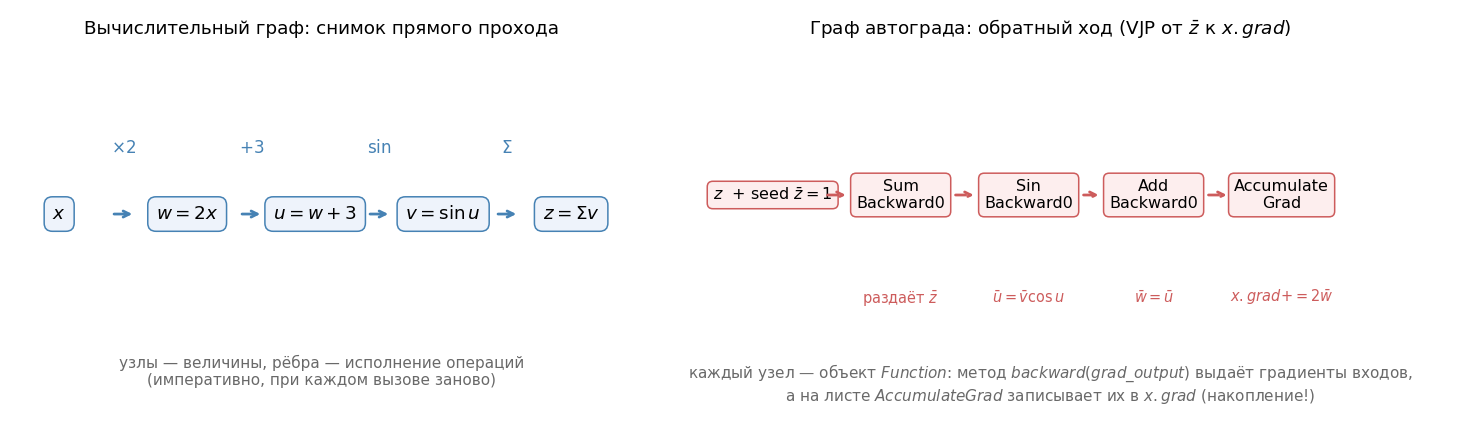

In [1]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.0))

ax = axes[0]
nodes_l = {'x': (0.07, 0.55), 'm': (0.28, 0.55), 'a': (0.49, 0.55), 's': (0.70, 0.55), 'z': (0.91, 0.55)}
vals = {'x': '$x$', 'm': '$w=2x$', 'a': '$u=w+3$', 's': '$v=\\sin u$', 'z': '$z=\\Sigma v$'}
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
for k, (px, py) in nodes_l.items():
    ax.text(px, py, vals[k], ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=0.45', fc='#eef3fb', ec='steelblue'))
for a, b, lab in [('x', 'm', '$\\times 2$'), ('m', 'a', '$+3$'),
                  ('a', 's', '$\\sin$'), ('s', 'z', '$\\Sigma$')]:
    xa, ya = nodes_l[a]; xb, yb = nodes_l[b]
    ax.annotate('', xy=(xb - 0.085, yb), xytext=(xa + 0.085, ya),
                arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.8))
    ax.text((xa + xb) / 2, ya + 0.16, lab, ha='center', fontsize=11, color='steelblue')
ax.text(0.5, 0.10, 'узлы — величины, рёбра — исполнение операций\n(императивно, при каждом вызове заново)',
        ha='center', fontsize=10, color='dimgray')
ax.set_title('Вычислительный граф: снимок прямого прохода', fontsize=12)

ax = axes[1]
chain = [('$z$  + seed $\\bar z=1$', (0.045, 0.60), ''),
         ('SumBackward0', (0.255, 0.60), 'раздаёт $\\bar z$'),
         ('SinBackward0', (0.465, 0.60), '$\\bar u=\\bar v\\cos u$'),
         ('AddBackward0', (0.670, 0.60), '$\\bar w=\\bar u$'),
         ('Accumulate\nGrad', (0.880, 0.60), '$x.grad\\!+\\!=2\\bar w$')]
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
for txt, (px, py), cap in chain:
    ax.text(px, py, txt.replace('Backward0', '\nBackward0'), ha='center', va='center', fontsize=10.5,
            bbox=dict(boxstyle='round,pad=0.35', fc='#fdeeee', ec='indianred'))
    if cap:
        ax.text(px, 0.33, cap, ha='center', va='center', fontsize=9.5, color='indianred')
for i in range(len(chain) - 1):
    (xa, ya), (xb, yb) = chain[i][1], chain[i + 1][1]
    ax.annotate('', xy=(xb - 0.085, yb), xytext=(xa + 0.085, ya),
                arrowprops=dict(arrowstyle='->', color='indianred', lw=1.8, linestyle='--'))
ax.text(0.5, 0.06, 'каждый узел — объект $Function$: метод $backward(grad\\_output)$ выдаёт градиенты входов,\n'
                   'а на листе $AccumulateGrad$ записывает их в $x.grad$ (накопление!)',
        ha='center', fontsize=10, color='dimgray')
ax.set_title('Граф автограда: обратный ход (VJP от $\\bar z$ к $x.grad$)', fontsize=12)

plt.tight_layout(); plt.show()


### 👢 Грабли и негладкости

- `.grad` по умолчанию у **листьев**; промежуточным нужны
  `retain_grad()` или `torch.autograd.grad(...)`;
- `detach()` и `torch.no_grad()` — «выключатели записи»: обновление
  весов, аугментация, инференс;
- `create_graph=True` — дифференцируется сам обратный проход (AD
  higher-order);
- повторный `backward()` **накапливает** `.grad` — не забудьте
  обнулять;
- **негладкие функции** (`relu`, `max`): в точке излома градиент не
  определён, движок молча вернёт условное значение — конвенция, а не
  математика 🩺;
- AD дифференцирует **реализацию, а не идею**: неустойчивая формула
  (softmax без вычитания максимума) переполнится вместе со своим
  градиентом — сперва устойчивая формула, потом дифференцирование.

Пробуем всё сразу:


In [1]:
import torch
import numpy as np
torch.manual_seed(0)

# 1) негладкая точка: производная relu в нуле — выбранная конвенция, не математика
xr = torch.linspace(-0.6, 0.6, 3, requires_grad=True)
torch.relu(xr).sum().backward()
print('x         :', [round(v, 2) for v in xr.detach().tolist()])
print('relu grad :', [round(v, 2) for v in xr.grad.tolist()], '← в нуле выбран 0')

# 2) устойчивость: сперва устойчивая формула, потом дифференцирование
z = torch.tensor([1000.0, 999.0])
with np.errstate(over='ignore', invalid='ignore'):
    print('наивная softmax  :', (np.exp(z) / np.exp(z).sum()).tolist())
print('torch.softmax    :', torch.softmax(z, 0).tolist(), '← вычитание max спасает')

# 3) gradcheck: направленные производные AD против центральных разностей
def g(p):
    return (p * torch.sin(p)).sum()

p = torch.randn(4, dtype=torch.float64, requires_grad=True)   # double обязателен
print('gradcheck        :', torch.autograd.gradcheck(g, (p,), eps=1e-6))


x         : [-0.6, 0.0, 0.6]
relu grad : [0.0, 0.0, 1.0] ← в нуле выбран 0
наивная softmax  : [nan, nan]
torch.softmax    : [0.7310585975646973, 0.2689414322376251] ← вычитание max спасает
gradcheck        : True


## 9. ⚖️ Сложность: время и память

Пусть $\Psi$ — число элементарных операций программы. Один проход AD
стоит порядка
$$
\text{cost} \sim c \,\Psi,
$$
где $c$ — небольшая константа. То есть **градиент той же стоимости,
что и функция**, с точностью до множителя. Отсюда и «быстрое» из
названия — при миллиардах параметров это разница между «обучаемо» и
«нет» 🏁.

| | прямой режим | обратный режим |
|---|---|---|
| 1 проход даёт | один **столбец** $J$ (JVP) | одну **строку** $J$ (VJP) |
| полное $J$ за | $n$ проходов | $m$ проходов |
| выбирать при | выходов много: $m \gg n$ | входов много: $n \gg m$ |
| память сверх функции | $O(1)$ | $O(L)$ — лента |

Полный якобиан — $\min(m, n)$ проходов: **режим выбирается по
короткой стороне якобиана**; при $m \approx n$ решают структура
графа, разреженность и память.

> 📜 **Теорема Баура–Штрассена (1983).** Для функции, вычисляемой
> арифметической прямолинейной программой, все первые производные
> можно получить с арифметической сложностью, отличающейся от
> сложности самой функции лишь постоянным множителем. Практика:
> арифметика растёт примерно в **2–3 раза**.

ML — предельный случай $n \gg m$: якобиан $1 \times n$, где
$n \sim 10^6 \dots 10^{11}$ параметров против одного скаляра потерь.
Обратный режим считает весь $\nabla L$ за один forward + один
backward; прямой потянул бы $n$ проходов. При $n$ в миллиарды эта
разница и есть причина, почему нейросети обучает именно обратный
режим, он же **backpropagation**.

> 🧠 Нюанс: накладные расходы обратного режима (писать ленту) заметны
> — при малом $n$ наивный прямой режим иногда выигрывает вплоть до
> $n \sim 100$. Правило не меняется: считаем короткую сторону якобиана.

Подозрительно дешёвый градиент? Проверим экспериментом. Функция —
«башня» тангенсов глубины $L$ с $L$ скалярными параметрами и одним
выходом: классический тест для AD. Сравниваем один обратный проход
с $L$ прямыми (по каждому параметру). 🗼


In [1]:
import numpy as np, time

def f_rev(ws, x):
    # прямой проход с лентой значений, затем обратный
    vals = [x]
    for w in ws:
        vals.append(np.tanh(w * vals[-1]))
    dws, adj = [], np.ones_like(x)
    for k in range(len(ws), 0, -1):
        prev, th = vals[k - 1], vals[k]
        dws.append((adj * (1 - th ** 2) * prev).sum())   # вклад в d/dw_k
        adj = adj * (1 - th ** 2) * ws[k - 1]
    return vals[-1], np.array(dws[::-1])

def f_fwd_one_dir(ws, x, i):
    # один прямой проход с касательной e_i (по параметру i)
    h, t = x, np.zeros_like(x)
    for k, w in enumerate(ws):
        th = np.tanh(w * h)
        t = (1 - th ** 2) * (w * t + (h if k == i else 0.0))
        h = th
    return h, t

rng = np.random.default_rng(0)
print(f"{'L слоёв':>8} | {'reverse (1 проход)':>18} | {'forward (L проходов)':>20} | отношение")
for L in [5, 20, 60]:
    ws = rng.uniform(-0.5, 0.5, L)
    x = rng.standard_normal(20000)
    val, g_rev = f_rev(ws, x)
    g_fwd = np.array([f_fwd_one_dir(ws, x, i)[1].sum() for i in range(L)])
    assert np.allclose(g_fwd, g_rev, atol=1e-8), 'режимы расходятся!'
    n = 20
    t0 = time.perf_counter()
    for _ in range(n):
        f_rev(ws, x)
    t_rev = (time.perf_counter() - t0) / n
    t0 = time.perf_counter()
    for _ in range(n):
        for i in range(L):
            f_fwd_one_dir(ws, x, i)
    t_fwd = (time.perf_counter() - t0) / n
    print(f'{L:8d} | {t_rev*1e3:14.2f} ms | {t_fwd*1e3:16.2f} ms | {t_fwd/t_rev:6.1f}x')

print()
print('отношение ~ L: обратный режим считается за цену 2-3 проходов функции,')
print('прямой — за L проходов. Градиент почти бесплатен по ВРЕМЕНИ;')
print('дорого его хранение (лента), но не вычисление.')


 L слоёв | reverse (1 проход) | forward (L проходов) | отношение
       5 |           2.73 ms |            13.15 ms |    4.8x
      20 |          11.24 ms |           214.23 ms |   19.1x
      60 |          37.93 ms |          1906.43 ms |   50.3x

отношение ~ L: обратный режим считается за цену 2-3 проходов функции,
прямой — за L проходов. Градиент почти бесплатен по ВРЕМЕНИ;
дорого его хранение (лента), но не вычисление.


Теперь бенчмарк на реальных размерах: якобиан линейного слоя
$\mathrm{predict}(x) = \tanh(Wx + b)$ по входу $x$. Форма якобиана —
$(D_{out}, D_{in})$: «высокая» или «широкая» — смотрим, какой режим
дешевле строит **весь** якобиан. ⏱️


In [1]:
import torch, time
torch.manual_seed(0)

def predict(W, b, x):
    return torch.tanh(x @ W.T + b)

def bench(fn, n=15):
    fn()                     # прогрев
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n

print(f"{'форма якобиана':>16} | {'jacfwd':>9} | {'jacrev':>9} | выигрывает")
for Din, Dout in [(32, 2048), (2048, 32)]:
    W = torch.randn(Dout, Din); b = torch.randn(Dout); x = torch.randn(Din)
    J1 = torch.func.jacfwd(predict, argnums=2)(W, b, x)
    J2 = torch.func.jacrev(predict, argnums=2)(W, b, x)
    assert torch.allclose(J1, J2, atol=1e-5), 'режимы расходятся!'
    t_fwd = bench(lambda: torch.func.jacfwd(predict, argnums=2)(W, b, x))
    t_rev = bench(lambda: torch.func.jacrev(predict, argnums=2)(W, b, x))
    win = 'jacfwd (прямой)' if t_fwd < t_rev else 'jacrev (обратный)'
    print(f'{str(tuple(J1.shape)):>16} | {t_fwd*1e3:7.2f} ms | {t_rev*1e3:7.2f} ms | {win}')

print()
print('высокая матрица (много выходов) -> jacfwd, широкая (много входов) -> jacrev.')


  форма якобиана |    jacfwd |    jacrev | выигрывает
      (2048, 32) |    1.96 ms |   12.70 ms | jacfwd (прямой)
      (32, 2048) |   11.02 ms |    1.31 ms | jacrev (обратный)

высокая матрица (много выходов) -> jacfwd, широкая (много входов) -> jacrev.


### 💾 Память: лента и чекпоинтинг

Прямому режиму хранить нечего (значение и касательная летят
вместе, надбавка $O(1)$). Обратному нужны **промежуточные значения
forward-прохода** — лента; у глубоких сетей это **активации**, и
именно они ограничивают размер батча. Но сохранять всё — не обязательно.

**Чекпоинтинг (rematerialization).** Храним лишь часть состояний
(контрольные точки), остальное **пересчитываем** в обратном проходе —
компромисс «меньше памяти ⇄ больше времени» ⚖️. Классический баланс
(Гриванк): сохраняя $O(\sqrt{L})$ состояний и пересчитывая блоки,
получаем память $O(\sqrt{L})$ вместо $O(L)$ ценой примерно
**+1 forward**. Экстремальный treeverse: память $O(\log L)$ за время
$O(L \log L)$. В PyTorch — `torch.utils.checkpoint`.

Проверим честные числа: сколько тензоров сохраняет небольшой блок и
сколько раз выполняется forward.


In [1]:
import torch
from torch.utils.checkpoint import checkpoint

x = torch.randn(1000, requires_grad=True)

def block(h):
    return torch.tanh(h) * h + torch.sin(h) ** 2

def measure(run):
    saved, calls = [], [0]
    def counted(h):
        calls[0] += 1
        return block(h)
    def pack(t):
        saved.append(t.numel())
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        run(counted)
    return len(saved), sum(saved), calls[0]

n1, e1, c1 = measure(lambda bl: bl(x).sum().backward())
n2, e2, c2 = measure(lambda bl: checkpoint(bl, x, use_reentrant=False).sum().backward())

print(f'без checkpoint: сохранено {n1} тензоров ({e1} элементов) | прямой проход {c1} раз')
print(f'с checkpoint:   сохранено {n2} тензоров ({e2} элементов) | прямой проход {c2} раза')
print('лента короче (память меньше), но блок пересчитан при backward —')
print('классическая сделка «память за время».')


без checkpoint: сохранено 5 тензоров (5000 элементов) | прямой проход 1 раз
с checkpoint:   сохранено 2 тензоров (1000 элементов) | прямой проход 2 раза
лента короче (память меньше), но блок пересчитан при backward —
классическая сделка «память за время».


---

## 10. 📚 Задачник для ПЗ

Задачи — теория + счёт руками (без кода). После каждой задачи
приложено **📕 развёрнутое решение** для преподавателя.

> ⚠️ *(решения лежат прямо в ноутбуке — перед раздачей слушателям их
> нужно удалить!)*


---

**Задача 1. Дуальные числа.**
В кольце $\mathbb{R}[\varepsilon]/\varepsilon^{2}$ ($\varepsilon^{2}
= 0$) вычислите значение и производную $f(x) = x^{3} - 2x$ в точке
$x = 2$, представив вход парой $2 + \varepsilon$.

---

**Задача 2. Две ленты.**
Для $f(x_1, x_2) = x_1 x_2 + \sin x_1$ в точке $(2, 3)$ постройте
целиком: (а) forward-ленту с primals и касательными по направлению
$e_1$; (б) backward-ленту сопряжённых с seed $\bar v = 1$.
Найдите $\nabla f$.

---

**Задача 3. JVP против VJP.**
Даны якобиан
$$
J = \begin{pmatrix} 1 & 2 & 0 \\ 0 & 1 & 3 \end{pmatrix},
\qquad
v = \begin{pmatrix} 1 \\ -1 \\ 2 \end{pmatrix},
\qquad
u = \begin{pmatrix} 2 \\ 1 \end{pmatrix}.
$$
(а) Вычислите $Jv$ и $u^{\top}J$. (б) Подсчитайте число умножений
и сложений в каждой из этих операций; какой из проходов дешевле
строит столбцы, какой — строки?

---

**Задача 4. Ромб и «+=».**
В примере $f = x_1 x_2 + \sin x_1$ узел $v_{-2}$ влияет на выход
по двум путям ($v_1$ и $v_2$). Объясните, почему сопряжённое нужно
**накапливать** («${+}{=}$»), а не перезаписывать («$=$»), и
посчитайте итоговое $\nabla f$. Что изменится, если поменять порядок
обработки узлов $v_1$ и $v_2$?

---

**Задача 5. Зачем лента?**
Почему обратному проходу нужен прямой проход **с сохранением
промежуточных значений**? Обоснуйте на операции
$v_1 = v_{-2}v_{-1}$ и на примере $f(x) = e^{x^{2}}$. Какая
альтернатива существует и какой ценой она достаётся?

---

**Задача 6. Backprop вручную.**
Для двухслойной сети
$z_1 = W_1 x + b_1$, $v_1 = \tanh z_1$, $z_2 = W_2 v_1 + b_2$,
$L = \frac{1}{2}(z_2 - y)^{2}$
выведите $\delta_2$, $\delta_1$ и $\frac{\partial L}{\partial W_1},
\frac{\partial L}{\partial W_2}$. Объясните, почему формулы δ —
не «четвёртый метод дифференцирования», а лишь разворот обратного
прохода.

---

**Задача 7. Сложность.**
Программа вычисляет $f \colon \mathbb{R}^{n} \to \mathbb{R}$ за
$\Psi = 10^{8}$ арифметических операций. Сколько операций и сколько
памяти (в терминах $\Psi$ и пары $(n, m)$) потребуется для
вычисления градиента $\nabla f \in \mathbb{R}^{n}$ прямым и
обратным режимом? Какой режим нужен SGD при $n = 10^{6}$ и почему.

---

**Задача 8. Раздувание символьного.**
В §2 считалось семейство $f_0 = x$, $f_k = f_{k-1}^{2} + 1$.
Оцените рост длины формулы $f_k$ и формулы $D[f_k]$ (рекурсивное
дифференцирование без упрощений). Почему возникает взрыв и почему
AD его не имеет.


### 📕 Решение 1 (дуальные числа).

Работаем в кольце: все степени $\varepsilon^{2}$ и выше обнуляются,
«доживают» только коэффициенты при $\varepsilon$. Пошаговая
арифметика при $x = 2 + \varepsilon$:
$$
x^{2} = (2 + \varepsilon)^{2} = 4 + 4\varepsilon + \varepsilon^{2}
= 4 + 4\varepsilon,
$$
$$
x^{3} = x^{2}\cdot x = (4 + 4\varepsilon)(2 + \varepsilon)
= 8 + (4 + 8)\varepsilon + 4\varepsilon^{2} = 8 + 12\varepsilon,
$$
$$
f(2 + \varepsilon) = x^{3} - 2x = (8 + 12\varepsilon) -
(4 + 2\varepsilon) = 4 + 10\varepsilon.
$$

Итого: значение $f(2) = 4$, касательная $f'(2) = 10$. Проверка
классикой: $f'(x) = 3x^{2} - 2 \Rightarrow f'(2) = 10$ ✔.
Обратите внимание: слагаемое $\varepsilon^{2}$ **выброшено правилом
кольца** — именно поэтому в касательной живёт ровно линейный член
разложения, и никакого усечения по $h$ не появляется: дуальная
алгебра «прячет» точность сама.

---

### 📕 Решение 2 (две ленты).

**(а) Forward-лента по направлению $e_1$** (primals + касательные):

| $i$ | операция | $v_i$ | $\tilde v_i$ |
|---|---|---|---|
| $-2$ | $v_{-2} = x_1$ | $2$ | $1$ |
| $-1$ | $v_{-1} = x_2$ | $3$ | $0$ |
| $1$ | $v_1 = v_{-2}\cdot v_{-1}$ | $6$ | $\tilde v_1 = 1\cdot 3 + 2\cdot 0 = 3$ |
| $2$ | $v_2 = \sin v_{-2}$ | $\sin 2$ | $\tilde v_2 = \cos 2$ |
| $3$ | $v_3 = v_1 + v_2$ | $6 + \sin 2$ | $\tilde v_3 = 3 + \cos 2$ |

Получили $\partial f/\partial x_1 = 3 + \cos 2$.

**(б) Backward-лента** ($\bar v_3 = 1$; локальные производные и
«${+}{=}$»):
$$
\bar v_2 = 1, \qquad \bar v_1 = 1, \qquad
\bar v_{-1} \,{+}{=}\, \bar v_1\, v_{-2} = 2, \qquad
\bar v_{-2} \,{+}{=}\, \bar v_1\, v_{-1} + \bar v_2\cos v_{-2}
= 3 + \cos 2.
$$
Итого $\nabla f = (3 + \cos 2,\; 2)$ ✔ — совпало с forward.
По числу арифметических операций оба прохода — $\Theta(\Psi)$:
**константа поверх стоимости самой функции**.

---

### 📕 Решение 3 (JVP против VJP).

**(а)** По правилам:
$$
Jv = \begin{pmatrix} 1 & 2 & 0 \\ 0 & 1 & 3 \end{pmatrix}
\begin{pmatrix} 1 \\ -1 \\ 2 \end{pmatrix}
= \begin{pmatrix} 1 - 2 \\ -1 + 6 \end{pmatrix}
= \begin{pmatrix} -1 \\ 5 \end{pmatrix},
$$
$$
u^{\top}J = 2\,(1, 2, 0) + 1\,(0, 1, 3) = (2,\; 5,\; 3).
$$

**(б) Счёт.** Умножение плотной матрицы $m \times n$ на вектор —
$m$ скалярных произведений длины $n$: $mn$ умножений
и $m(n-1)$ сложений. Здесь $m = 2$, $n = 3$: 6 умножений и
4 сложения — **одинаково** для $Jv$ и $u^{\top}J$ (операция
$u^{\top}J$ — это $m$-длинные строки с $n$ скалярными
произведениями, цена та же). Разница — в **режиме AD**: JVP за
один прямой проход даёт ровно один столбец, VJP за один обратный —
ровно одну строку. Полный якобиан — $\min(m, n)$ проходов; при
$m = 1$ (скалярные потери) VJP в один проход тянет весь градиент
$\nabla f$, при $m \gg n$ выигрывает прямой режим.

---

### 📕 Решение 4 (ромб и «+=»).

У узла $v_{-2}$ два исходящих ребра: $v_{-2} \to v_1$ и
$v_{-2} \to v_2$ («ромб», diamond 💎). Обратный проход обходит
узлы в обратном топологическом порядке; когда оба рёбра обработаны,
$\bar v_{-2}$ получил **вклады из двух источников**:
$$
\bar v_{-2} = \underbrace{\bar v_1\, v_{-1}}_{\text{через}\; v_1}
+ \underbrace{\bar v_2\, \cos v_{-2}}_{\text{через}\; v_2}
= 1\cdot 3 + 1\cdot \cos 2 = 3 + \cos 2.
$$
Причина накопления: цепное правило для «вилки» требует **суммы
вкладов** всех путей. Если бы вместо «${+}{=}$» писали «$=$»,
последнее обработанное ребро стёрло бы предыдущий вклад: при порядке
($v_2$, затем $v_1$) осталась бы только cos-часть, при обратном
порядке — только «умножная» часть $3$; правильная сумма
$3 + \cos 2$ не набралась бы никогда. «${+}{=}$» делает результат
**независимым от порядка обхода**. В PyTorch то же свойство:
`AccumulateGrad` накапливает, а не заменяет — при повторных
`backward()` происходит `.grad += .`.


---

### 📕 Решение 5 (зачем лента).

Локальные производные зависят от **значений**: правило
$v_1 = v_{-2}v_{-1}$ в обратном проходе требует уже вычисленных
$v_{-1}$, $v_{-2}$; для $f(x) = e^{x^{2}}$ производная элемента —
$f'(x) = e^{x^{2}}\cdot 2x$, и $e^{x^{2}}$, и $x$ должны быть
**числами**, когда долетел cotangent. Пересчитать их «на ходу» внутри
обратного прохода нельзя: назад мы идём по ленте, не имея данных,
какие входы были израсходованы выше. Альтернатива — **повторные
прямые проходы**: перезапускать forward для восстановления нужных
значений (добавка до $O(L)$ проходов, вплоть до $O(\Psi L)$
времени). Компромисс — **чекпоинтинг** (§9): сохранять не всё, а
контрольные точки и пересчитывать сегменты — при разбиении на
$\sqrt{L}$ блоков память $O(\sqrt{L})$, время — примерно
$+1$ проход. Именно так тренируются очень глубокие сети,
которые иначе не влезают в память GPU.

---

### 📕 Решение 6 (backprop вручную).

Прямой проход:
$$
z_1 = W_1 x + b_1, \quad v_1 = \tanh z_1, \quad
z_2 = W_2 v_1 + b_2, \quad L = \tfrac{1}{2}(z_2 - y)^{2}.
$$
Ошибки слоёв:
$$
\delta_2 = \frac{\partial L}{\partial z_2} = z_2 - y, \qquad
\delta_1 = \bigl(W_2^{\top} \delta_2\bigr) \odot \tanh'(z_1)
= \bigl(W_2^{\top} \delta_2\bigr) \odot (1 - \tanh^{2} z_1).
$$
Градиенты параметров:
$$
\frac{\partial L}{\partial W_2} = \delta_2\, v_1^{\top}, \qquad
\frac{\partial L}{\partial b_2} = \delta_2, \qquad
\frac{\partial L}{\partial W_1} = \delta_1\, x^{\top}, \qquad
\frac{\partial L}{\partial b_1} = \delta_1.
$$

Это та же механика обратного прохода, развёрнутая на конкретном
слоистом графе: $\delta_k$ — просто сопряжённые узлов $z_k$, а
«распространение ошибки» — накопление «${+}{=}$» на рёбрах. Иного
принципа нет: AD работает на **любом** графе и получает те же числа
автоматически; δ-формулы — интерпретация и учебник для ручного счёта.
Поэтому ни одна новая архитектура (ветвления, residual, attention)
не требует «нового вывода backprop» — движок дифференцирует граф как
есть.

---

### 📕 Решение 7 (сложность).

При $m = 1$ якобиан — строка $1 \times n$.

- **Обратный режим:** один forward ($\Psi$ операций) + один backward
  (по теореме Баура–Штрассена — с константным множителем $c \le 3$):
  итого $\sim (c + 1)\Psi \approx 3\cdot 10^{8}$ операций.
  Память: лента $O(L)$ узлов $\approx 10^{8}$ значений float32
  $\approx$ 400 МБ (в реальном обучении лимит — активации батчей);
  спасает чекпоинтинг.
- **Прямой режим:** столбец $Je_j$ за один проход, но полный
  градиент требует $n$ проходов:
  $n \cdot c\,\Psi \approx 10^{6} \cdot 2 \cdot 10^{8}
  \approx 2\cdot 10^{14}$ операций. Память $O(1)$ сверх функции,
  но время неоправданно.

Вывод: SGD на каждом шаге требует только $\nabla f$ при $m = 1$ —
незаменим обратный режим. Прямой уместен при $m \gg n$ (много
выходов): производные активаций, кривизна через HVP и т.п.

---

### 📕 Решение 8 (раздувание символьного).

Длина $f_k$ растёт **линейно**: каждый шаг добавляет к записи
«^2 + 1» и пару скобок (в таблице §2: 8, 17, 26, ..., т.е.
$|f_k| = 9k - 1$ знаков); дерево тоже линейно, «квадрат + сложение».

А длина $D[f_k]$: правило $D[f_k] = 2 f_{k-1} \cdot D[f_{k-1}]$
в дереве производной на каждом шаге несёт **целое дерево
$f_{k-1}$** (ссылки на поддеревья невозможны — символьные выражения
не умеют ссылаться) плюс дерево $D[f_{k-1}]$:
$$
|D[f_k]| \gtrsim |f_{k-1}| + |D[f_{k-1}]|
\quad \Rightarrow \quad
|D[f_k]| \sim \sum_{j < k} |f_j| \sim k^{2},
$$
рост **квадратичный**; для семейств с вложенными композициями
(«башни» $\exp \circ \exp \circ \dots$) — уже
экспоненциальный. Взрыв — цена правил, которые дублируют
поддеревья во всех своих мономах ($D[uv] = u'v + uv'$ и т.п.);
подробный разбор — у Гриванка и Уолтера, *Evaluating Derivatives*.

AD взрыва не имеет: формулы даже не строятся. На каждом примитиве
локальное правило применяется к **числам** — на узел расходуется
$O(1)$ работы и памяти (только касательные/сопряжённые узлов), а по
Бауру–Штрассену полная стоимость градиента отличается от стоимости
функции лишь константой. Именно поэтому для нейросети с миллиардами
операций «формула градиента» вообще не существует — есть только числа.


---

> 🧭 **Мостик к следующим лекциям.** AD дал градиент любой программы
> за константу по стоимости — топливо 🛢️ для оптимизационных методов.
> Дальше: градиентные методы первого порядка (спуск), ньютоновские
> методы (якобианы и Гессианы через JVP/VJP), нелинейные уравнения.
> А в ПЗ (Раздел 1) уже ждёт МНК с базисными сплайнами (Л5) — там
> дифференцирование потерь тоже ляжет на обратный режим из этой
> лекции.
